<a href="https://colab.research.google.com/github/Daniel220503/Machine-Learning-2026-Agost-Dic/blob/main/Hands_on_3_Regresion_Polinomial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hands-on 3: Regresión en Machine Learning — Polynomial Regression

**Modalidad:** personal  
**Herramientas:** Python, NumPy, pandas, Matplotlib, SciPy y scikit-learn  
**Material de referencia:** [Six Sigma Material – Regression](https://www.six-sigma-material.com/Regression.html)

## Objetivo
Mostrar **paso a paso** cómo implementar una **Regresión Polinomial** con scikit-learn, ajustando una curva de grado **n = 4** (n > 3), siguiendo cada etapa del *pipeline* de Machine Learning.

## Caso de estudio (tomado de la página de referencia)
En la página, un *Black Belt* de Six Sigma estudia cómo el **tamaño de lote** (*Batch Size*, variable predictora **X**) afecta la **eficiencia de la máquina** (*Machine Efficiency*, variable respuesta **Y**). El rango de datos va de 25 a 115 piezas por lote, y la relación **no es lineal**: la eficiencia sube rápido al inicio y luego se aplana.

## Contenido
1. Fundamentos teóricos del *Least Squared Regressor*
2. Modelo matemático y analítico
3. Pipeline de Machine Learning
   - 3.1 Recolección de datos
   - 3.2 Descripción y análisis del dataset
   - 3.3 Scatter plot
   - 3.4 Preparación de los datos (train/test y escalado)
   - 3.5 Selección y entrenamiento del modelo
   - 3.6 Verificación analítica (ecuación normal)
   - 3.7 Predicción y curva ajustada
   - 3.8 Evaluación (métricas)
   - 3.9 Análisis de residuos
   - 3.10 Comparación de grados
4. Conclusiones

## 1. Fundamentos teóricos del *Least Squared Regressor* para el ajuste de curvas

**Regresión:** conjunto de procesos estadísticos para estimar la relación entre una variable dependiente (respuesta, **Y**) y una o más variables independientes (regresoras, predictoras o *features*, **X**).

**Jerga básica** (según la página de referencia):

| Término | Significado |
|---|---|
| Variable respuesta (Y) | Salida que queremos explicar/predecir |
| Variable regresora (X) | Entrada que afecta a la respuesta |
| Ecuación de regresión | Describe la relación entre X y Y |
| Residuo | Diferencia entre el valor observado y el valor predicho |

**Método de Mínimos Cuadrados (*Least Squares*):** encuentra la curva que **minimiza la suma de los cuadrados de los residuos**. Es decir, de todas las curvas posibles, elige la que deja el menor error total al cuadrado.

**R² (coeficiente de determinación):** porcentaje de la variación de Y que explica el modelo.

$$R^2 = \frac{SS_{regresión}}{SS_{total}} = 1 - \frac{SS_{error}}{SS_{total}}, \qquad SS_{total} = SS_{regresión} + SS_{error}$$

Un R² alto suele indicar mejor ajuste, pero **no basta**: hay que revisar los residuos.

**Supuestos sobre los residuos** (para que el modelo sea válido):
- Son **independientes**.
- Siguen una **distribución normal** con media 0.
- Tienen **varianza constante** (homocedasticidad).

**Rango de inferencia:** el modelo solo es confiable dentro del rango de X con el que se entrenó (aquí, de 25 a 115). Fuera de ese rango, las predicciones pueden ser incorrectas.

**¿Por qué polinomial?** Cuando la relación entre X y Y es curva, una recta no ajusta bien. La regresión polinomial agrega potencias de X ($x^2, x^3, x^4, \dots$) como nuevas variables y luego aplica mínimos cuadrados. Por eso sigue siendo un modelo **lineal en los coeficientes**, aunque la curva resultante sea no lineal en X.

## 2. Modelo matemático y analítico

### 2.1 Modelo polinomial de grado $n$

$$\hat{y} = \beta_0 + \beta_1 x + \beta_2 x^2 + \beta_3 x^3 + \dots + \beta_n x^n$$

En este tutorial usamos **n = 4**:

$$\hat{y} = \beta_0 + \beta_1 x + \beta_2 x^2 + \beta_3 x^3 + \beta_4 x^4$$

### 2.2 Forma matricial
Con $m$ observaciones, se construye la **matriz de diseño** $\Phi$ (columnas: $1, x, x^2, \dots, x^n$):

$$\Phi = \begin{bmatrix} 1 & x_1 & x_1^2 & \cdots & x_1^n \\ 1 & x_2 & x_2^2 & \cdots & x_2^n \\ \vdots & & & & \vdots \\ 1 & x_m & x_m^2 & \cdots & x_m^n \end{bmatrix}, \qquad \hat{\mathbf{y}} = \Phi\boldsymbol{\beta}$$

### 2.3 Función de costo (suma de cuadrados del error)

$$J(\boldsymbol{\beta}) = SS_{error} = \sum_{i=1}^{m}\left(y_i - \hat{y}_i\right)^2 = \lVert \mathbf{y} - \Phi\boldsymbol{\beta}\rVert^2$$

### 2.4 Solución analítica (ecuación normal)
Derivando $J$ respecto a $\boldsymbol{\beta}$ e igualando a cero:

$$\frac{\partial J}{\partial \boldsymbol{\beta}} = -2\Phi^\top(\mathbf{y}-\Phi\boldsymbol{\beta}) = 0 \;\;\Rightarrow\;\; \boxed{\boldsymbol{\beta} = (\Phi^\top\Phi)^{-1}\Phi^\top \mathbf{y}}$$

### 2.5 Métricas de evaluación

$$MAE = \frac{1}{m}\sum|y_i-\hat{y}_i| \qquad MSE = \frac{1}{m}\sum(y_i-\hat{y}_i)^2 \qquad RMSE=\sqrt{MSE}$$

$$R^2 = 1-\frac{\sum(y_i-\hat{y}_i)^2}{\sum(y_i-\bar{y})^2} \qquad R^2_{ajustado} = 1-(1-R^2)\frac{m-1}{m-p-1}$$

donde $p$ es el número de términos del polinomio (sin contar el intercepto).

## 3. Pipeline de Machine Learning

Etapas que seguiremos: **recolección → descripción/análisis → visualización → preparación → entrenamiento → predicción → evaluación**.

### 3.0 Importación de librerías

In [1]:
import numpy as np                                   # NumPy: operaciones numéricas y matrices
import pandas as pd                                  # pandas: manejo de datos en tablas (DataFrame)
import matplotlib.pyplot as plt                      # Matplotlib: gráficas
from scipy import stats                              # SciPy stats: pruebas estadísticas (normalidad)
from sklearn.model_selection import train_test_split # Función para dividir datos en entrenamiento y prueba
from sklearn.preprocessing import StandardScaler, PolynomialFeatures  # Escalado y generación de potencias de X
from sklearn.linear_model import LinearRegression    # Modelo de mínimos cuadrados (Least Squares)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score  # Métricas de evaluación

np.random.seed(42)                                   # Semilla para que los resultados sean reproducibles
plt.rcParams["figure.figsize"] = (8, 5)              # Tamaño por defecto de las gráficas

### 3.1 Recolección de datos

La página de referencia muestra su tabla de datos como imagen, así que **no se pueden descargar los valores originales**. Para poder reproducir el estudio, se **simula un dataset** con la misma lógica del ejemplo:

- **X = Batch Size** (tamaño de lote) entre **25 y 115**, el mismo rango de inferencia de la página.
- **Y = Machine Efficiency** (%), generada con la ecuación cúbica que reporta la página, más **ruido aleatorio** (para imitar mediciones reales):

$$Y = 65.07 - 0.8923X + 0.02565X^2 - 0.000136X^3 + \varepsilon, \quad \varepsilon \sim N(0,\,2^2)$$

> **Nota:** si tuvieras datos reales, aquí se cargarían con `pd.read_csv("archivo.csv")`.

In [2]:
n_muestras = 80                                                   # Número de observaciones (lotes) a generar
batch_size = np.random.uniform(25, 115, n_muestras)               # X: tamaños de lote aleatorios entre 25 y 115
ruido = np.random.normal(0, 2, n_muestras)                        # Ruido aleatorio normal (media 0, desviación 2)
eficiencia = (65.07 - 0.8923 * batch_size                         # Término constante y término lineal de la página
              + 0.02565 * batch_size**2                           # Término cuadrático de la página
              - 0.000136 * batch_size**3                          # Término cúbico de la página
              + ruido)                                            # Se suma el ruido para simular mediciones reales
eficiencia = np.clip(eficiencia, 0, 100)                          # La eficiencia no puede exceder 100% ni ser negativa

df = pd.DataFrame({                                               # Se crea la tabla (DataFrame) con los datos
    "Batch_Size": batch_size.round(1),                            # Columna X redondeada a 1 decimal
    "Machine_Efficiency": eficiencia.round(2)                     # Columna Y redondeada a 2 decimales
})
df.head(10)                                                       # Se muestran las primeras 10 filas

,Batch_Size,Machine_Efficiency
0,58.7,74.23
1,110.6,98.11
2,90.9,92.79
3,78.9,87.16
4,39.0,59.02
5,39.0,58.84
6,30.2,59.40
7,103.0,99.38
8,79.1,87.52
9,88.7,94.84


### 3.2 Descripción y análisis del dataset
Revisamos tamaño, tipos de datos, valores faltantes, estadísticos descriptivos y correlación.

In [ ]:
print("Dimensiones (filas, columnas):", df.shape)      # Cuántas observaciones y columnas tiene el dataset
print("\nTipos de datos y nulos:")                     # Encabezado informativo
df.info()                                              # Resumen: tipos de dato y conteo de valores no nulos
print("\nValores nulos por columna:")                  # Encabezado informativo
print(df.isnull().sum())                               # Cuenta los valores faltantes en cada columna

Dimensiones (filas, columnas): (80, 2)

Tipos de datos y nulos:
<class 'pandas.DataFrame'>
RangeIndex: 80 entries, 0 to 79
Data columns (total 2 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Batch_Size          80 non-null     float64
 1   Machine_Efficiency  80 non-null     float64
dtypes: float64(2)
memory usage: 1.4 KB

Valores nulos por columna:
Batch_Size            0
Machine_Efficiency    0
dtype: int64


In [3]:
df.describe()                                          # Estadísticos: media, desviación, mínimo, cuartiles y máximo

,Batch_Size,Machine_Efficiency
count,80.000000,80.000000
mean,66.935000,77.683125
std,27.512644,15.287508
min,25.500000,53.640000
25%,41.575000,62.777500
50%,64.250000,77.900000
75%,91.775000,93.410000
max,113.800000,100.000000


In [ ]:
corr = df["Batch_Size"].corr(df["Machine_Efficiency"]) # Coeficiente de correlación de Pearson entre X y Y
print(f"Correlación de Pearson: {corr:.4f}")           # Se imprime con 4 decimales

Correlación de Pearson: 0.9766


**Interpretación:** la correlación de Pearson mide únicamente la asociación **lineal**. Aunque salga alta, eso no garantiza que una recta sea el mejor modelo; la gráfica de dispersión nos dirá si la relación es curva.

### 3.3 Scatter plot (diagrama de dispersión)

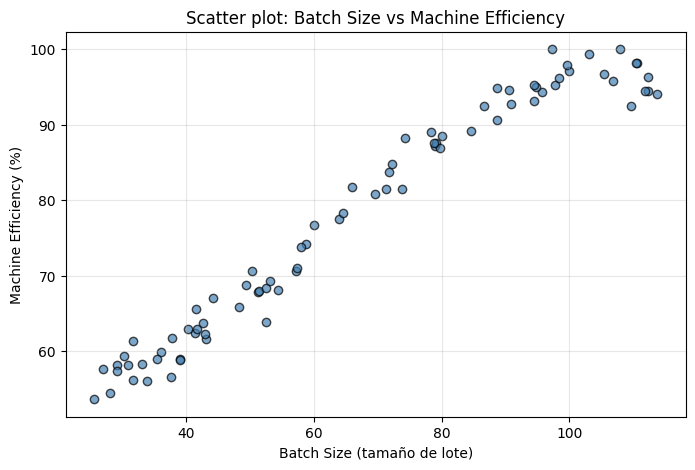

In [4]:
plt.scatter(df["Batch_Size"], df["Machine_Efficiency"],   # Dibuja cada observación como un punto (X, Y)
            color="steelblue", alpha=0.7, edgecolor="k")  # Color azul, algo transparente y con borde negro
plt.xlabel("Batch Size (tamaño de lote)")                 # Etiqueta del eje X
plt.ylabel("Machine Efficiency (%)")                      # Etiqueta del eje Y
plt.title("Scatter plot: Batch Size vs Machine Efficiency")  # Título de la gráfica
plt.grid(alpha=0.3)                                       # Cuadrícula suave de fondo
plt.show()                                                # Muestra la gráfica

**Observación:** los puntos forman una **curva** (crece rápido y luego se aplana), no una línea recta. Por eso una regresión lineal simple se quedaría corta y conviene un modelo polinomial.

### 3.4 Preparación de los datos
1. **Separar X e Y.** scikit-learn exige que X sea una matriz 2D.
2. **División entrenamiento/prueba (80/20):** entrenamos con una parte y evaluamos con datos que el modelo nunca vio.
3. **Escalado (estandarización):** las potencias de X crecen muy rápido (con X = 115, $X^4 \approx 1.7\times10^8$). Estandarizar evita problemas numéricos.

In [7]:
X = df[["Batch_Size"]].values                              # X como matriz 2D (m filas, 1 columna)
y = df["Machine_Efficiency"].values                        # y como vector 1D con la variable respuesta

X_train, X_test, y_train, y_test = train_test_split(       # Divide los datos en entrenamiento y prueba
    X, y, test_size=0.2, random_state=42)                  # 20% para prueba; semilla fija para reproducir
print("Datos de entrenamiento:", X_train.shape[0])         # Cantidad de observaciones de entrenamiento
print("Datos de prueba:", X_test.shape[0])                 # Cantidad de observaciones de prueba

Datos de entrenamiento: 64
Datos de prueba: 16


In [8]:
scaler = StandardScaler()                                  # Crea el escalador (resta la media y divide entre la desviación)
X_train_s = scaler.fit_transform(X_train)                  # Aprende media/desviación SOLO del entrenamiento y lo transforma
X_test_s = scaler.transform(X_test)                        # Aplica la misma transformación a los datos de prueba
print("Media X_train escalado:", X_train_s.mean().round(4))   # Debe ser aproximadamente 0
print("Desv. X_train escalado:", X_train_s.std().round(4))    # Debe ser aproximadamente 1

Media X_train escalado: -0.0
Desv. X_train escalado: 1.0


### 3.5 Selección y entrenamiento del modelo

Usamos **grado 4** (n > 3, como pide la actividad). El proceso tiene dos pasos:

1. `PolynomialFeatures(degree=4)` convierte cada X en $[x, x^2, x^3, x^4]$.
2. `LinearRegression` aplica **mínimos cuadrados** sobre esas columnas.

In [9]:
grado = 4                                                  # Grado del polinomio (n = 4, cumple n > 3)
poly = PolynomialFeatures(degree=grado, include_bias=False)  # Genera x, x², x³, x⁴ (el intercepto lo agrega el modelo)
X_train_p = poly.fit_transform(X_train_s)                  # Transforma X de entrenamiento en sus potencias
X_test_p = poly.transform(X_test_s)                        # Transforma X de prueba con la misma regla
print("Forma de X_train_p:", X_train_p.shape)              # Ahora hay 4 columnas: x, x², x³, x⁴
print("Nombres de las columnas:", poly.get_feature_names_out(["x"]))  # Muestra qué representa cada columna

Forma de X_train_p: (64, 4)
Nombres de las columnas: ['x' 'x^2' 'x^3' 'x^4']


In [10]:
modelo = LinearRegression()                                # Crea el regresor de mínimos cuadrados
modelo.fit(X_train_p, y_train)                             # ENTRENA: calcula los coeficientes que minimizan SS_error
print("Intercepto (β0):", round(modelo.intercept_, 4))     # Coeficiente constante
for i, c in enumerate(modelo.coef_, start=1):              # Recorre los coeficientes de cada potencia
    print(f"Coeficiente β{i} (x^{i}):", round(c, 4))       # Imprime β1, β2, β3 y β4

Intercepto (β0): 79.1573
Coeficiente β1 (x^1): 19.8111
Coeficiente β2 (x^2): -0.7388
Coeficiente β3 (x^3): -2.7431
Coeficiente β4 (x^4): -0.278


> Los coeficientes están en la **escala estandarizada** de X, por eso no coinciden con los de la ecuación de la página. Lo que importa es que la **curva resultante** sea equivalente.

### 3.6 Verificación analítica (ecuación normal)

Comprobamos que lo que hizo scikit-learn coincide con la fórmula del apartado 2.4: $\boldsymbol{\beta} = (\Phi^\top\Phi)^{-1}\Phi^\top \mathbf{y}$.

In [11]:
Phi = np.c_[np.ones(X_train_p.shape[0]), X_train_p]        # Matriz de diseño Φ: columna de unos + potencias de X
XtX = Phi.T @ Phi                                          # Producto Φᵀ·Φ
Xty = Phi.T @ y_train                                      # Producto Φᵀ·y
beta = np.linalg.solve(XtX, Xty)                           # Resuelve (ΦᵀΦ)β = Φᵀy (equivale a la ecuación normal)

print("β (ecuación normal):", beta.round(4))               # Coeficientes calculados a mano
print("β (scikit-learn)   :", np.r_[modelo.intercept_, modelo.coef_].round(4))  # Coeficientes de scikit-learn
print("¿Son iguales?      :", np.allclose(beta, np.r_[modelo.intercept_, modelo.coef_]))  # Verifica la coincidencia

β (ecuación normal): [79.1573 19.8111 -0.7388 -2.7431 -0.278 ]
β (scikit-learn)   : [79.1573 19.8111 -0.7388 -2.7431 -0.278 ]
¿Son iguales?      : True


### 3.7 Predicción y curva ajustada

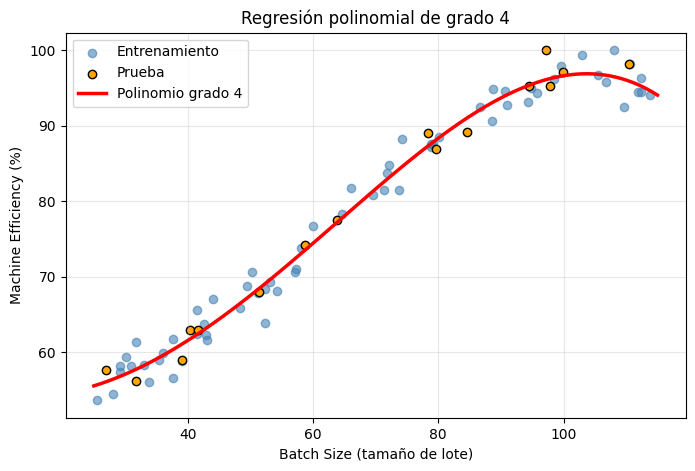

In [12]:
y_pred_train = modelo.predict(X_train_p)                   # Predicciones sobre los datos de entrenamiento
y_pred_test = modelo.predict(X_test_p)                     # Predicciones sobre los datos de prueba (no vistos)

x_curva = np.linspace(25, 115, 300).reshape(-1, 1)         # 300 valores de X uniformes dentro del rango de inferencia
y_curva = modelo.predict(poly.transform(scaler.transform(x_curva)))  # Aplica escalado → potencias → modelo

plt.scatter(X_train, y_train, color="steelblue", alpha=0.6, label="Entrenamiento")  # Puntos de entrenamiento
plt.scatter(X_test, y_test, color="orange", edgecolor="k", label="Prueba")          # Puntos de prueba
plt.plot(x_curva, y_curva, color="red", linewidth=2.5, label=f"Polinomio grado {grado}")  # Curva ajustada
plt.xlabel("Batch Size (tamaño de lote)")                  # Etiqueta del eje X
plt.ylabel("Machine Efficiency (%)")                       # Etiqueta del eje Y
plt.title("Regresión polinomial de grado 4")               # Título de la gráfica
plt.legend()                                               # Muestra la leyenda
plt.grid(alpha=0.3)                                        # Cuadrícula suave
plt.show()                                                 # Muestra la gráfica

**Ejemplo de predicción (como en la página):** el departamento de Finanzas fija el tamaño de lote en **65**. ¿Qué eficiencia esperamos? La página obtiene aproximadamente **78%**.

In [13]:
lote_nuevo = np.array([[65]])                              # Nuevo tamaño de lote a evaluar (dentro de 25–115)
lote_nuevo_p = poly.transform(scaler.transform(lote_nuevo))  # Se escala y se generan las potencias
eficiencia_65 = modelo.predict(lote_nuevo_p)[0]            # Se predice la eficiencia
print(f"Eficiencia estimada con lote = 65: {eficiencia_65:.2f}%")  # Resultado con 2 decimales

Eficiencia estimada con lote = 65: 78.04%


### 3.8 Evaluación de la técnica (métricas)

In [14]:
def evaluar(y_real, y_est, p):                             # Función que calcula todas las métricas
    m = len(y_real)                                        # Número de observaciones
    mae = mean_absolute_error(y_real, y_est)               # Error absoluto medio
    mse = mean_squared_error(y_real, y_est)                # Error cuadrático medio
    rmse = np.sqrt(mse)                                    # Raíz del error cuadrático medio
    r2 = r2_score(y_real, y_est)                           # Coeficiente de determinación R²
    r2_adj = 1 - (1 - r2) * (m - 1) / (m - p - 1)          # R² ajustado por número de términos
    return {"MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2, "R2 ajustado": r2_adj}  # Devuelve un diccionario

res = pd.DataFrame({                                       # Tabla comparativa entrenamiento vs prueba
    "Entrenamiento": evaluar(y_train, y_pred_train, grado),  # Métricas con datos de entrenamiento
    "Prueba": evaluar(y_test, y_pred_test, grado)          # Métricas con datos de prueba
}).round(4)                                                # Redondeo a 4 decimales
res                                                        # Se muestra la tabla

,Entrenamiento,Prueba
MAE,1.5052,1.2830
MSE,3.6396,2.5124
RMSE,1.9078,1.5851
R2,0.9839,0.9899
R2 ajustado,0.9828,0.9862


**Cómo leerla:**
- **R²** cercano a 1 → el modelo explica casi toda la variación de Y (la página reporta ≈ 97.9% en su ejemplo).
- **RMSE y MAE** están en las mismas unidades de Y (puntos porcentuales de eficiencia): indican el error típico de predicción.
- Si las métricas de **entrenamiento y prueba son parecidas**, no hay sobreajuste (*overfitting*).

### 3.9 Análisis de residuos
La página insiste en que **no basta con el R²**: hay que revisar que los residuos sean aleatorios, normales y de varianza constante.

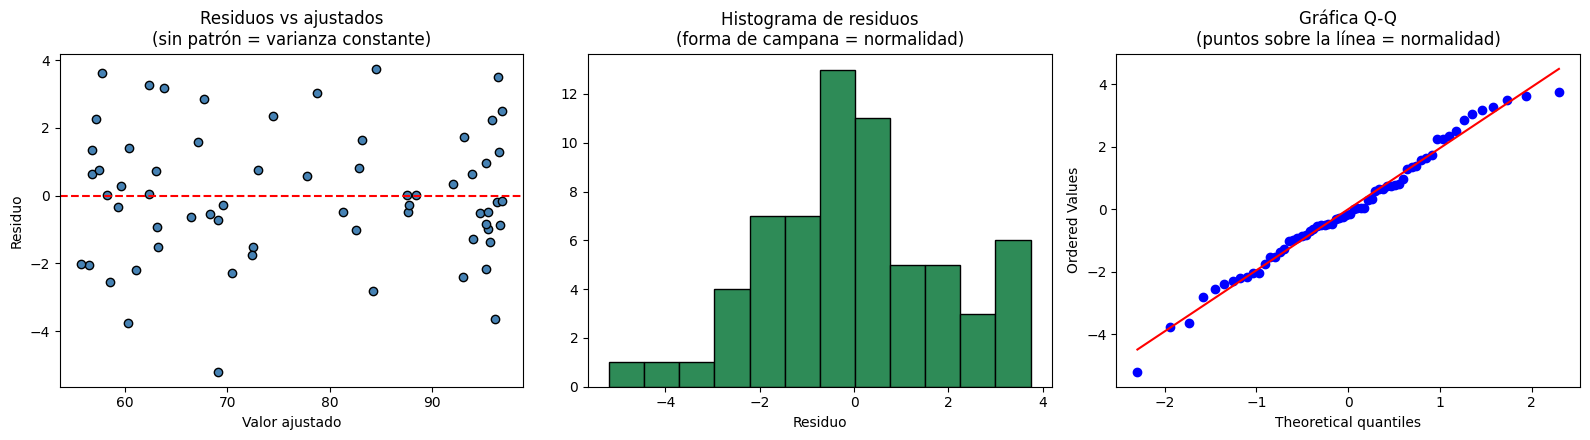

In [15]:
residuos = y_train - y_pred_train                          # Residuo = valor observado − valor predicho

fig, ejes = plt.subplots(1, 3, figsize=(16, 4.5))          # Figura con 3 gráficas en una fila

ejes[0].scatter(y_pred_train, residuos, color="steelblue", edgecolor="k")  # Residuos vs valores ajustados
ejes[0].axhline(0, color="red", linestyle="--")            # Línea de referencia en cero
ejes[0].set_title("Residuos vs ajustados\n(sin patrón = varianza constante)")  # Título
ejes[0].set_xlabel("Valor ajustado")                       # Etiqueta X
ejes[0].set_ylabel("Residuo")                              # Etiqueta Y

ejes[1].hist(residuos, bins=12, color="seagreen", edgecolor="k")  # Histograma de los residuos
ejes[1].set_title("Histograma de residuos\n(forma de campana = normalidad)")  # Título
ejes[1].set_xlabel("Residuo")                              # Etiqueta X

stats.probplot(residuos, dist="norm", plot=ejes[2])        # Gráfica Q-Q para comparar con una normal
ejes[2].set_title("Gráfica Q-Q\n(puntos sobre la línea = normalidad)")  # Título

plt.tight_layout()                                         # Ajusta espacios entre gráficas
plt.show()                                                 # Muestra las gráficas

In [16]:
stat, p_valor = stats.shapiro(residuos)                    # Prueba de Shapiro-Wilk (H0: los residuos son normales)
print(f"Media de los residuos: {residuos.mean():.4f}")     # Debe ser aproximadamente 0
print(f"Shapiro-Wilk: estadístico = {stat:.4f}, p-valor = {p_valor:.4f}")  # Resultado de la prueba
if p_valor > 0.05:                                         # Se compara contra alfa = 0.05
    print("p > 0.05 → no se rechaza la normalidad de los residuos ✔")  # Supuesto cumplido
else:                                                      # Si p ≤ 0.05
    print("p ≤ 0.05 → los residuos podrían no ser normales ✘")         # Supuesto en duda

Media de los residuos: 0.0000
Shapiro-Wilk: estadístico = 0.9856, p-valor = 0.6612
p > 0.05 → no se rechaza la normalidad de los residuos ✔


### 3.10 Comparación de grados (underfitting vs overfitting)
Probamos grados 1 a 6 para ver cómo cambia el ajuste. El grado 1 es una recta (subajuste); un grado muy alto puede sobreajustar.

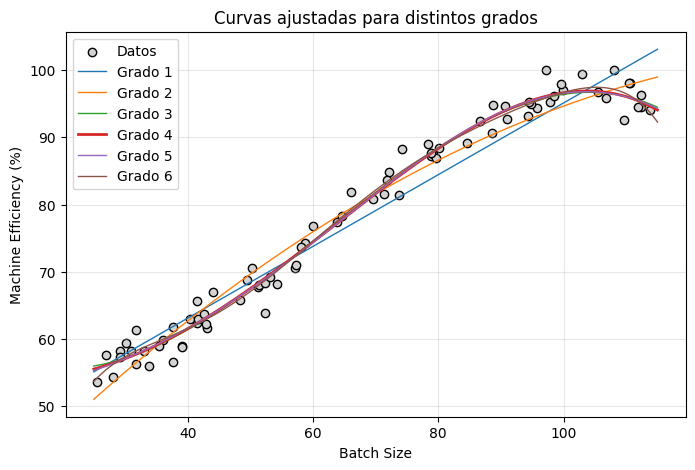

,Grado,R2 train,R2 test,RMSE test
0,1,0.9495,0.9665,2.8792
1,2,0.9673,0.9726,2.6066
2,3,0.9838,0.9898,1.5885
3,4,0.9839,0.9899,1.5851
4,5,0.9839,0.9895,1.6108
5,6,0.9847,0.9890,1.6541


In [17]:
filas = []                                                 # Lista donde guardaremos los resultados de cada grado
plt.scatter(X, y, color="lightgray", edgecolor="k", label="Datos")  # Puntos originales de fondo

for g in range(1, 7):                                      # Recorre los grados del 1 al 6
    sc = StandardScaler().fit(X_train)                     # Nuevo escalador ajustado con el entrenamiento
    pf = PolynomialFeatures(degree=g, include_bias=False)  # Generador de potencias de grado g
    Xtr = pf.fit_transform(sc.transform(X_train))          # Potencias del entrenamiento
    Xte = pf.transform(sc.transform(X_test))               # Potencias de la prueba
    m = LinearRegression().fit(Xtr, y_train)               # Entrena el modelo de grado g
    filas.append({                                         # Guarda las métricas de este grado
        "Grado": g,                                        # Grado del polinomio
        "R2 train": r2_score(y_train, m.predict(Xtr)),     # R² en entrenamiento
        "R2 test": r2_score(y_test, m.predict(Xte)),       # R² en prueba
        "RMSE test": np.sqrt(mean_squared_error(y_test, m.predict(Xte)))  # RMSE en prueba
    })
    plt.plot(x_curva, m.predict(pf.transform(sc.transform(x_curva))),  # Dibuja la curva de este grado
             label=f"Grado {g}", linewidth=2 if g == grado else 1)     # El grado 4 se resalta más

plt.xlabel("Batch Size")                                   # Etiqueta del eje X
plt.ylabel("Machine Efficiency (%)")                       # Etiqueta del eje Y
plt.title("Curvas ajustadas para distintos grados")        # Título
plt.legend()                                               # Leyenda
plt.grid(alpha=0.3)                                        # Cuadrícula
plt.show()                                                 # Muestra la gráfica

pd.DataFrame(filas).round(4)                               # Tabla comparativa de métricas por grado

**Lectura:** el grado 1 (recta) tiene el peor ajuste, confirmando que la relación es curva. Del grado 3 en adelante el R² casi no mejora: **agregar más grados no aporta** y solo complica el modelo. El grado 4 (el pedido en la actividad) ajusta muy bien y se mantiene estable entre entrenamiento y prueba.

## 4. Conclusiones

1. La relación entre el **tamaño de lote** y la **eficiencia de la máquina** es **no lineal**: crece rápido entre ~40 y ~80 y se aplana cerca de 100, igual que en el ejemplo de la página.
2. La **regresión polinomial de grado 4** (n > 3) ajusta correctamente la curva y obtiene un **R² alto** tanto en entrenamiento como en prueba, sin señales de sobreajuste.
3. La solución de **mínimos cuadrados** de scikit-learn coincide con la **ecuación normal** $\boldsymbol{\beta}=(\Phi^\top\Phi)^{-1}\Phi^\top\mathbf{y}$, lo que valida el modelo matemático.
4. El **análisis de residuos** (aleatorios, normales, varianza constante) es necesario para confirmar que el modelo es válido; el R² por sí solo no es suficiente.
5. El modelo solo debe usarse dentro del **rango de inferencia (25–115)**; extrapolar fuera de él puede dar predicciones poco confiables (por ejemplo, un lote de 0 daría una eficiencia irreal).
6. Subir el grado más allá de lo necesario **no mejora** el desempeño y aumenta el riesgo de sobreajuste.

## Referencias
- Six Sigma Material. *Linear, Non-Linear, and Multiple Regression*. https://www.six-sigma-material.com/Regression.html
- Pedregosa et al. (2011). *Scikit-learn: Machine Learning in Python*. JMLR 12, 2825–2830.